# Tiền xử lý và làm sạch dữ liệu bất động sản

**Đề tài 06:** Dự báo giá bất động sản đô thị (Urban Real Estate Valuation & Hedonic Pricing)

## 1. Mô tả dữ liệu

Tập dữ liệu gồm 3.500 tin rao bán nhà ở tại Hà Nội và Thành phố Hồ Chí Minh, với 21 thuộc tính, ở dạng thô như khi thu thập từ các trang rao vặt bất động sản. Dữ liệu chứa nhiều dạng lỗi phổ biến của dữ liệu thu thập tự động: giá trị số được ghi dưới dạng văn bản, sai đơn vị đo, cách viết không thống nhất, lỗi mã hóa ký tự, bản ghi trùng lặp và dòng không hợp lệ.

Notebook này thực hiện quy trình làm sạch nhằm tạo ra tập dữ liệu nhất quán, đúng kiểu, sẵn sàng cho các bước phân tích và mô hình hóa.

| Vai trò | Tệp | Số bản ghi |
|---|---|---|
| Dữ liệu đầu vào | `data/raw/vietnam_housing_dirty.csv` | 3.510 (bao gồm dòng không hợp lệ) |
| Dữ liệu đầu ra | `data/processed/clean.csv` | 2.945 |
| Nhật ký xử lý | `reports/cleaning_log.csv` | Số bản ghi sau từng bước |

## 2. Hướng dẫn thực thi

**Yêu cầu môi trường:** Python 3.9 trở lên, các thư viện trong `requirements.txt` (cài đặt bằng `pip install -r requirements.txt`).

**Các bước thực hiện:**
1. Mở notebook bằng Jupyter Notebook, JupyterLab hoặc một trình soạn thảo có hỗ trợ Jupyter.
2. Chọn kernel Python của môi trường ảo dự án (`.venv`).
3. Thực thi toàn bộ notebook (*Run All*). Thời gian thực thi khoảng 10 giây.
4. Kiểm tra kết quả ở ô cuối cùng: thông báo `Đã lưu 2945 dòng vào data/processed/clean.csv` cho biết quá trình làm sạch đã hoàn tất.

**Lưu ý:** Các ô được thiết kế để chạy tuần tự từ trên xuống, ô sau sử dụng kết quả của ô trước. Khi chạy từng ô riêng lẻ, cần giữ đúng thứ tự; nếu thứ tự bị gián đoạn, khởi động lại kernel (*Restart Kernel*) và chạy lại từ đầu.

## 3. Cấu trúc notebook

| Phần | Nội dung |
|---|---|
| 1. Import thư viện | Khai báo các thư viện sử dụng |
| 2. Đọc dữ liệu | Khai báo đường dẫn và nạp tệp dữ liệu gốc |
| 3. Tiền xử lý | 19 bước (3.1 → 3.19): loại bỏ dòng không hợp lệ, chuẩn hóa văn bản, chuyển đổi kiểu dữ liệu, xử lý giá trị bất thường, loại bỏ trùng lặp. Mỗi bước trình bày kết quả trước và sau xử lý |
| 4. Lưu kết quả | Ghi tập dữ liệu sạch và nhật ký xử lý |

Quy trình có tính tất định: mỗi lần thực thi đều cho cùng một kết quả. Tệp đầu ra được ghi đè sau mỗi lần chạy; tệp dữ liệu gốc không bị thay đổi.

## 4. Mô tả tập dữ liệu đầu ra (`clean.csv`)

| Thuộc tính | Ý nghĩa |
|---|---|
| `order`, `url`, `title`, `posted_date` | Số thứ tự, đường dẫn, tiêu đề, ngày đăng tin |
| `city`, `district`, `house_type` | Thành phố, quận/huyện, loại nhà (`Nhà mặt tiền` / `Nhà trong hẻm`) |
| `area_m2`, `width_m`, `length_m`, `road_width_m` | Diện tích (m²), chiều ngang, chiều dài, độ rộng đường trước nhà (m) |
| `floors`, `bedrooms` | Số tầng, số phòng ngủ |
| `has_dining_room`, `has_kitchen`, `has_terrace`, `has_parking` | Có phòng ăn, nhà bếp, sân thượng, chỗ đỗ ô tô |
| `price_billion_vnd` | **Giá rao bán (tỷ VNĐ)**, biến mục tiêu |
| `price_from_title`, `title_price_mismatch`, `location_fix` | Cờ đánh dấu bản ghi đã được hiệu chỉnh: giá lấy từ tiêu đề, giá không khớp tiêu đề, quận/huyện lấy từ địa chỉ hoặc tiêu đề |

Các giá trị còn thiếu (`width_m`, `length_m`, `floors`...) được giữ nguyên ở bước này. Việc điền giá trị thiếu được thực hiện trong giai đoạn mô hình hóa, sau khi phân chia tập huấn luyện và tập kiểm thử, nhằm tránh rò rỉ thông tin từ tập kiểm thử (*data leakage*).

## 5. Sử dụng dữ liệu đầu ra

Ở giai đoạn mô hình hóa, tập dữ liệu sạch được chia thành tập huấn luyện (80%) và tập kiểm thử độc lập (20%). Tham số `random_state` được cố định để kết quả phân chia có thể tái lập.

```python
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/processed/clean.csv")
train, test = train_test_split(df, test_size=0.2, random_state=4595)
```

## 6. Nguồn dữ liệu

Các thuộc tính về đặc điểm nhà và giá được trích từ dữ liệu thu thập trên alonhadat.com.vn (khoảng năm 2021), công bố tại [AndrewBui-AI-CS/House_price_prediction](https://github.com/AndrewBui-AI-CS/House_price_prediction). Các thuộc tính `url`, `title`, `address`, `posted_date`, `contact`, `scraped_at` cùng các lỗi trong dữ liệu được bổ sung nhân tạo nhằm phục vụ mục đích thực hành làm sạch dữ liệu.

**Hạn chế:** giá trong dữ liệu là giá rao bán, không phải giá giao dịch thực tế; dữ liệu phản ánh thị trường năm 2021.

# 1. Import thư viện

In [1]:
from __future__ import annotations

import datetime as dt      # xử lý ngày tháng
import difflib             # so khớp chuỗi gần giống (sửa chính tả tên quận)
import html                # bỏ ký tự HTML như &nbsp;
import re                  # biểu thức chính quy (tìm số trong chữ)
import unicodedata         # chuẩn hóa Unicode tiếng Việt
from pathlib import Path   # đường dẫn file

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 50)

print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)

numpy      2.0.2
pandas     2.3.3
matplotlib 3.9.4


# 2. Đọc dữ liệu

### Đường dẫn file
Notebook nằm trong `notebooks/`, nên thư mục dự án là thư mục cha.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "vietnam_housing_dirty.csv"
CLEAN_PATH = ROOT / "data" / "processed" / "clean.csv"
LOG_PATH = ROOT / "reports" / "cleaning_log.csv"

print("Đọc từ :", RAW_PATH)
print("Ghi ra :", CLEAN_PATH)
print("File gốc tồn tại:", RAW_PATH.exists())

Đọc từ : /Users/hoangvinh/Project/estate-predict/data/raw/vietnam_housing_dirty.csv
Ghi ra : /Users/hoangvinh/Project/estate-predict/data/processed/clean.csv
File gốc tồn tại: True


### Đọc file CSV
- `dtype=str`: đọc mọi cột dạng chữ, giữ nguyên giá trị gốc (ví dụ `5ty2`).
- `keep_default_na=False`: không tự đổi ô trống, `NaN`, `null`... thành NaN; ta tự xử lý ở bước sau.

In [3]:
raw = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
log = [("Dữ liệu thô", len(raw))]   # ghi lại số dòng sau mỗi bước

print("Số dòng, số cột:", raw.shape)
raw.head(10)

Số dòng, số cột: (3510, 21)


,order,url,title,address,posted_date,city,district,house_type,area_m2,width_m,length_m,road_width_m,floors,bedrooms,has_dining_room,has_kitchen,has_terrace,has_parking,price_billion_vnd,contact,scraped_at
0,1,https://alonhadat.com.vn/ban-nha-trong-hem-cau...,🔥🔥 Siêu phẩm nhà trong hẻm Cầu Giấy - 108m2 - ...,"Hà Nội, Cầu Giấy",2021-12-02,Hà Nội,Quận Cầu Giấy,Nhà trong hẻm,0108,6.8,,3.0,5.0,5.0,True,True,True,True,69.4 triệu/m²,,2021-12-17T18:50:00
1,2,https://alonhadat.com.vn/ban-nha-mat-tien-hoan...,Bán nhà Hoàn Kiếm... LH chính chủ,"Hanoi, Hoàn Kiếm",2021-09-09,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,1100.0,6.3,--,15.0,1.0,3.0.0,False,có bếp,không,False,27000,Liên hệ chính chủ,2021-12-15T17:24:00
2,3,https://batdongsan.com.vn/ban-nha-trong-hem-ba...,"Nhà đẹp Bắc Từ Liêm ô tô đỗ cửa, 25m, giá 1.65ty",Bắc Từ Liêm - Hà Nội,2021-07-26,Hà Nội,Bắc Từ Liêm,Hẻm,25.0,3.5,8.0,3.0,4.0,3.0,True,True,ko,False,,Hiện số,2021-12-07T20:22:00
3,4,https://alonhadat.com.vn/ban-nha-trong-hem-go-...,Bán nhà Gò Vấp... LH chính chủ,Gò Vấp,09/03/2021,Hồ Chí Minh,Gò Vấp.,Nhà trong hẻm,24.0,3.0,8.0,8.0,2.0,2.0,no,False,Không,0,"2,9 tỷ VNĐ",Hiện số,2021-12-14T09:41:00
4,5,https://nhadat247.com.vn/ban-nha-mat-tien-long...,Bán nhà Long Biên 70m2 4 tầng giá 7 tỷ,"Long Biên, Hà Nội",2021-06-19,Hà Nội,Quận Long Biên,Nhà mặt tiền,70.0,"7,0",,5.0,4.0,6.0,True,True,True,True,7.0,Liên hệ chính chủ,2021-12-13T04:53:00
5,6,https://alonhadat.com.vn/ban-nha-trong-hem-ha-...,"Chính chủ bán nhà Hà Đông, DT 55m², 5T, giá 11 tỷ",Hà Đông,2021-07-14,Hà Nội,HÀ ĐÔNG,Nhà trong hẻm,55.0,"4,0",,15.0,5.0,4.0,không,False,False,False,"11,000,000,000 đ",091.979.xxx,2021-12-05T22:24:00
6,7,https://batdongsan.com.vn/ban-nha-trong-hem-ho...,Hạ giá! 🔥🔥 Siêu phẩm nhà trong hẻm Hoàng Mai -...,,Hôm nay,Hà Nội,hoàng mai,Nhà trong hẻm,65.0,,,6.0,4.0,4+,False,N,False,False,6.18,Liên hệ chính chủ,2021-12-07T00:01:00
7,8,https://alonhadat.com.vn/ban-nha-trong-hem-10-...,BÁN GẤP NHÀ TRONG HẺM QUẬN 10 105M2 CHỈ 16.7 TỶ,,21/08/2021,Hồ Chí Minh,10,nhà ngõ,5.9x20.0,5.9,20.0,5.0,0.0,4.0,False,FALSE,False,False,16.7,035 220 ***,2021-12-20T12:09:00
8,9,https://alonhadat.com.vn/ban-nha-trong-hem-ha-...,Bán nhà Hà Đông 33m2 3 tầng giá 3.5 tỷ,Hà Đông,3/5/21,Hà Nội,Hà Đông,Nhà trong hẻm,330.0,3.0m,,6.0,3.0,3.0,True,True,True,True,3500,097 639 ***,2021-12-14T01:48:00
9,10,https://alonhadat.com.vn/ban-nha-mat-tien-than...,"Chính chủ bán nhà Thanh Xuân, DT 42m², 5T, giá...","Hà Nội, Thanh Xuân",15/09/2021,Hà Nội,Thanh Suân,Mặt tiền,42.0,4.2,8.5,3.0,5.0,4.0,True,True,yes,True,2-Thg5,035 434 ***,11/12/2021 21:05


In [4]:
# Danh sách cột
raw.columns.tolist()

['order',
 'url',
 'title',
 'address',
 'posted_date',
 'city',
 'district',
 'house_type',
 'area_m2',
 'width_m',
 'length_m',
 'road_width_m',
 'floors',
 'bedrooms',
 'has_dining_room',
 'has_kitchen',
 'has_terrace',
 'has_parking',
 'price_billion_vnd',
 'contact',
 'scraped_at']

# 3. Tiền xử lý (làm sạch dữ liệu)
Mỗi ô làm một việc và in kết quả ngay bên dưới. Chạy lần lượt từ trên xuống.

## 3.1 Bỏ dòng tiêu đề bị lặp
Khi gộp nhiều file crawl, dòng tiêu đề (`order, url, title...`) bị chèn vào giữa dữ liệu.

In [5]:
print("Dòng tiêu đề lặp:")
display(raw[raw["order"] == "order"].iloc[:, :6])

df = raw[raw["order"] != "order"].copy()
log.append(("Bỏ dòng tiêu đề lặp", len(df)))
print(f"Trước: {len(raw)} dòng  ->  Sau: {len(df)} dòng")

Dòng tiêu đề lặp:


,order,url,title,address,posted_date,city
507,order,url,title,address,posted_date,city
904,order,url,title,address,posted_date,city
2418,order,url,title,address,posted_date,city
3485,order,url,title,address,posted_date,city


Trước: 3510 dòng  ->  Sau: 3506 dòng


## 3.2 Bỏ dòng rỗng
Dòng chỉ có dấu phẩy, mọi ô đều trống.

In [6]:
empty = (df == "").all(axis=1)
print("Số dòng rỗng:", empty.sum())

n = len(df)
df = df[~empty].copy()
log.append(("Bỏ dòng rỗng", len(df)))
print(f"Trước: {n} dòng  ->  Sau: {len(df)} dòng")

Số dòng rỗng: 6
Trước: 3506 dòng  ->  Sau: 3500 dòng


## 3.3 Sửa dòng bị lệch cột
Dòng bị thiếu một ô ở đoạn `title/address/posted_date`, nên các cột phía sau dồn sang trái một ô. Dấu hiệu: `scraped_at` trống và `contact` lại chứa thời gian.

In [7]:
COLUMNS = [
    "order", "url", "title", "address", "posted_date", "city", "district", "house_type",
    "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms",
    "has_dining_room", "has_kitchen", "has_terrace", "has_parking",
    "price_billion_vnd", "contact", "scraped_at",
]
BOOL_COLS = ["has_dining_room", "has_kitchen", "has_terrace", "has_parking"]

shifted = (df["scraped_at"] == "") & df["contact"].str.match(r"^\d{4}-\d{2}-\d{2}T|^\d{2}/\d{2}/\d{4} ")
show = ["order", "city", "district", "house_type", "area_m2", "price_billion_vnd", "contact", "scraped_at"]
print("Số dòng lệch cột:", shifted.sum())
print("TRƯỚC khi sửa:")
display(df.loc[shifted, show].head())

Số dòng lệch cột: 11
TRƯỚC khi sửa:


,order,city,district,house_type,area_m2,price_billion_vnd,contact,scraped_at
615,615,Q. 1,Nhà mặt tiền,66.0,,090138****,2021-12-01T17:58:00,
844,842,Huyện Cầu Giấy,Nhà mặt tiền,66.0,600,Hiện số,2021-12-16T07:45:00,
973,970,Đống Đa,nhà ngõ,70.0,6.0,035.373.xxx,03/12/2021 08:35,
1328,1325,Cầu Giấy,Nhà trong hẻm,60.0,,Liên hệ chính chủ,2021-12-11T15:02:00,
1578,1575,Cầu Giấy,Nhà mặt tiền,65.0,520,,20/12/2021 01:22,


In [8]:
# Dời các cột từ city trở đi sang phải một ô
i_city = COLUMNS.index("city")
for idx in df.index[shifted]:
    vals = df.loc[idx, COLUMNS].tolist()
    df.loc[idx, COLUMNS[i_city:]] = vals[i_city - 1:-1]
    df.loc[idx, ["title", "address", "posted_date"]] = ""   # không biết ô nào bị mất nên để trống

log.append((f"Sửa {int(shifted.sum())} dòng lệch cột", len(df)))
print("SAU khi sửa:")
df.loc[shifted, show].head()

SAU khi sửa:


,order,city,district,house_type,area_m2,price_billion_vnd,contact,scraped_at
615,615,Hồ Chí Minh,Q. 1,Nhà mặt tiền,66.0,48500 triệu,090138****,2021-12-01T17:58:00
844,842,Hà Nội,Huyện Cầu Giấy,Nhà mặt tiền,66.0,18.0,Hiện số,2021-12-16T07:45:00
973,970,Hà Nội,Đống Đa,nhà ngõ,70.0,7.0 tỷ VNĐ,035.373.xxx,03/12/2021 08:35
1328,1325,Hà nội,Cầu Giấy,Nhà trong hẻm,60.0,,Liên hệ chính chủ,2021-12-11T15:02:00
1578,1575,Hà Nội,Cầu Giấy,Nhà mặt tiền,65.0,11.0,,20/12/2021 01:22


## 3.4 Chuẩn hóa chữ
Sửa lỗi font (mojibake), chuẩn hóa Unicode, bỏ HTML/emoji, bỏ khoảng trắng thừa, đổi các ký hiệu thiếu (`N/A`, `-`, `?`, `null`...) thành NaN.

In [9]:
MISSING_TOKENS = {"", "nan", "null", "none", "n/a", "na", "-", "--", "?", "không rõ", "khong ro"}


EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F]")


def fix_mojibake(s: str) -> str:
    """Sửa chữ UTF-8 bị đọc nhầm thành Latin-1, ví dụ 'Cáº§u Giáº¥y' -> 'Cầu Giấy'."""
    if re.search("[ÃÂÄÆáº»]", s):
        try:
            return s.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s
    return s


def clean_text(x) -> str | float:
    """Chuẩn hóa một ô chữ: sửa font, NFC, bỏ HTML/emoji/khoảng trắng thừa."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    s = fix_mojibake(str(x))
    s = unicodedata.normalize("NFKC", s)  # NFC + đổi số full-width về số thường
    s = html.unescape(s).replace("\xa0", " ")
    s = re.sub(r"<[^>]+>", " ", s)
    s = EMOJI_RE.sub(" ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return np.nan if s.lower() in MISSING_TOKENS else s


# Thử hàm
for s in ["Cáº§u Giáº¥y", "<b>Nhà trong hẻm</b>", "🔥 Mặt tiền 🔥", "  Hà nội ", "N/A", "６.５"]:
    print(f"{s!r:28} -> {clean_text(s)!r}")

'Cáº§u Giáº¥y'               -> 'Cầu Giấy'
'<b>Nhà trong hẻm</b>'       -> 'Nhà trong hẻm'
'🔥 Mặt tiền 🔥'               -> 'Mặt tiền'
'  Hà nội '                  -> 'Hà nội'
'N/A'                        -> nan
'６.５'                        -> '6.5'


In [10]:
before = df.copy()
for c in df.columns:
    df[c] = df[c].map(clean_text)

result = pd.DataFrame({
    "ô trống trước": (before == "").sum(),
    "NaN sau": df.isna().sum(),
})
print("Số ô thiếu ở mỗi cột (sau khi gom các ký hiệu thiếu về NaN):")
result

Số ô thiếu ở mỗi cột (sau khi gom các ký hiệu thiếu về NaN):


,ô trống trước,NaN sau
order,0,0
url,0,0
title,11,11
address,463,463
posted_date,45,68
city,0,2
district,0,109
house_type,0,0
area_m2,0,0
width_m,903,997


## 3.5 Thành phố
Gom các cách viết (`HN`, `Hanoi`, `TPHCM`, `Sài Gòn`...) về 2 giá trị. Sửa dòng bị đổi chỗ thành phố/quận. Ô nào vẫn trống thì lấy từ cột `address`.

In [11]:
HN, HCM = "Hà Nội", "Hồ Chí Minh"


DISTRICTS = {
    HN: ["Ba Đình", "Hoàn Kiếm", "Hai Bà Trưng", "Đống Đa", "Tây Hồ", "Cầu Giấy", "Thanh Xuân",
         "Hoàng Mai", "Long Biên", "Bắc Từ Liêm", "Nam Từ Liêm", "Hà Đông", "Sơn Tây", "Thanh Trì",
         "Gia Lâm", "Đông Anh", "Sóc Sơn", "Hoài Đức", "Thanh Oai", "Chương Mỹ", "Mê Linh",
         "Đan Phượng", "Thường Tín", "Quốc Oai", "Thạch Thất", "Phúc Thọ", "Ba Vì", "Mỹ Đức",
         "Ứng Hòa", "Phú Xuyên"],
    HCM: [f"Quận {i}" for i in range(1, 13)] + [
        "Bình Thạnh", "Gò Vấp", "Phú Nhuận", "Tân Bình", "Tân Phú", "Bình Tân", "Thủ Đức",
        "Nhà Bè", "Hóc Môn", "Củ Chi", "Bình Chánh", "Cần Giờ"],
}


DISTRICT_ALIASES = {"hbt": "Hai Bà Trưng"}


def ascii_key(s: str) -> str:
    """Bỏ dấu, chữ thường, chỉ giữ chữ và số: 'Đống Đa' -> 'dongda'."""
    s = str(s).replace("Đ", "D").replace("đ", "d")
    s = unicodedata.normalize("NFD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", s)


CITY_KEYS = {
    "hanoi": HN, "hn": HN, "tphanoi": HN,
    "hochiminh": HCM, "hcm": HCM, "tphcm": HCM, "tphochiminh": HCM, "saigon": HCM,
    "thanhphohochiminh": HCM,
}


def parse_city(x) -> str | float:
    if pd.isna(x):
        return np.nan
    return CITY_KEYS.get(ascii_key(x), np.nan)


_DIST_INDEX = {}


for _city, _names in DISTRICTS.items():
    for _name in _names:
        _key = ascii_key(_name.replace("Quận ", ""))
        _DIST_INDEX[_key] = (_city, _name)


def parse_district(x, city=None) -> tuple[str, str] | None:
    """Trả về (thành phố, tên quận chuẩn) hoặc None nếu không nhận ra."""
    if pd.isna(x):
        return None
    s = re.sub(r"^\s*(quận|huyện|thị xã|thành phố|tp\.?|q\.?)\s*", "", str(x), flags=re.IGNORECASE)
    key = ascii_key(s)
    if not key:
        return None
    if key in DISTRICT_ALIASES:
        key = ascii_key(DISTRICT_ALIASES[key])
    if key in _DIST_INDEX:
        return _DIST_INDEX[key]
    if key.isdigit():
        return None
    pool = [k for k, (c, _) in _DIST_INDEX.items() if city is None or c == city]
    match = difflib.get_close_matches(key, pool, n=1, cutoff=0.8)
    return _DIST_INDEX[match[0]] if match else None


def parse_address(x) -> tuple[str | float, str | float]:
    """Tách (thành phố, quận) từ chuỗi địa chỉ."""
    city = district = np.nan
    if pd.isna(x):
        return city, district
    for part in re.split(r"[,\-]", str(x)):
        part = part.strip()
        if not part or part.startswith("Đường") or ascii_key(part) == "vietnam":
            continue
        c = parse_city(part)
        if not pd.isna(c):
            city = c
            continue
        d = parse_district(part)
        if d:
            district = d[1]
            if pd.isna(city):
                city = d[0]
    return city, district


def district_from_title(t, city) -> str | None:
    """Tìm tên quận trong tiêu đề, ví dụ 'Bán nhà Quận 10 37m2...' -> 'Quận 10'."""
    if pd.isna(t):
        return None
    m = re.search(r"quận (\d{1,2})\b", str(t), flags=re.IGNORECASE)
    if m and city in (HCM, None) and 1 <= int(m.group(1)) <= 12:
        return f"Quận {int(m.group(1))}"
    key = ascii_key(t)
    for c, names in DISTRICTS.items():
        if city is not None and not pd.isna(city) and c != city:
            continue
        for name in sorted(names, key=len, reverse=True):
            if not name.startswith("Quận ") and ascii_key(name) in key:
                return name
    return None


# Thử hàm
for s in ["HN", "Sài Gòn", "tp hồ chí minh"]:
    print(f"{s!r:18} -> {parse_city(s)}")
for s in ["Q. 10", "Huyện Cầu Giấy", "Thanh Suân", "HBT", "Đốngđa", "Ha ong"]:
    print(f"{s!r:18} -> {parse_district(clean_text(s))}")

'HN'               -> Hà Nội
'Sài Gòn'          -> Hồ Chí Minh
'tp hồ chí minh'   -> Hồ Chí Minh
'Q. 10'            -> ('Hồ Chí Minh', 'Quận 10')
'Huyện Cầu Giấy'   -> ('Hà Nội', 'Cầu Giấy')
'Thanh Suân'       -> ('Hà Nội', 'Thanh Xuân')
'HBT'              -> ('Hà Nội', 'Hai Bà Trưng')
'Đốngđa'           -> ('Hà Nội', 'Đống Đa')
'Ha ong'           -> ('Hà Nội', 'Hà Đông')


In [12]:
print("TRƯỚC:", df["city"].nunique(), "cách viết")
display(df["city"].value_counts().head(15))

city = df["city"].map(parse_city)
district_raw = df["district"].copy()

# Thành phố và quận bị đổi chỗ cho nhau
swap = city.isna() & df["district"].map(parse_city).notna()
city[swap] = df.loc[swap, "district"].map(parse_city)
district_raw[swap] = df.loc[swap, "city"]

# Lấy từ địa chỉ nếu vẫn trống
addr = df["address"].map(parse_address)
addr_city = addr.map(lambda t: t[0])
addr_dist = addr.map(lambda t: t[1])
city = city.fillna(addr_city)

print("Số dòng đổi chỗ thành phố/quận:", swap.sum())
print("SAU:")
city.value_counts(dropna=False)

TRƯỚC: 48 cách viết


city
Hà Nội            1591
Hồ Chí Minh        780
HN                 135
Ha Noi             123
Hà nội             122
TP Hà Nội          120
hà nội             119
Hanoi              108
tp hồ chí minh      70
TPHCM               63
Ho Chi Minh         62
HCM                 54
TP.HCM              53
Sài Gòn             42
Tân Bình             5
Name: count, dtype: int64

Số dòng đổi chỗ thành phố/quận: 58
SAU:


city
Hà Nội         2349
Hồ Chí Minh    1151
Name: count, dtype: int64

## 3.6 Quận
Đưa về tên chuẩn, sửa chính tả/mất dấu. Quận không thuộc thành phố thì lấy từ `address` hoặc tiêu đề.

In [13]:
districts, flags = [], []
for raw_d, c, ad, title in zip(district_raw, city, addr_dist, df["title"]):
    d = parse_district(raw_d, c if not pd.isna(c) else None)
    # số trơn ('1', '12'...) chỉ có ở TP.HCM
    if d is None and not pd.isna(raw_d) and re.sub(r"\D", "", str(raw_d)) and c == HCM:
        n = int(re.sub(r"\D", "", str(raw_d)))
        d = (HCM, f"Quận {n}") if 1 <= n <= 12 else None
    if d and (pd.isna(c) or d[0] == c):
        districts.append(d[1]); flags.append("")
    elif not pd.isna(ad):
        districts.append(ad); flags.append("lay_tu_dia_chi")
    elif (td := district_from_title(title, c)) is not None:
        districts.append(td); flags.append("lay_tu_tieu_de")
    else:
        districts.append(np.nan); flags.append("khong_xac_dinh" if d is None else "quan_sai_tp")

print("TRƯỚC:", df["district"].nunique(), "cách viết")
df["city"] = city
df["district"] = districts
df["location_fix"] = flags
print("SAU  :", df["district"].nunique(), "quận")
print()
print(df["location_fix"].value_counts().rename("số dòng được sửa"))
pd.DataFrame({"Trước": before["district"], "Sau": df["district"]}).drop_duplicates().sample(15, random_state=1)

TRƯỚC: 199 cách viết
SAU  : 39 quận

location_fix
                  3330
lay_tu_dia_chi     155
lay_tu_tieu_de      15
Name: số dòng được sửa, dtype: int64


,Trước,Sau
344,Tây Hồ,Tây Hồ
1241,Hoàng Mai,Tân Phú
3449,Q. 8,Quận 8
195,Nam Từ Liêm,Nam Từ Liêm
111,Thanh Xuân,Thanh Xuân
538,Nam Tu Liem,Nam Từ Liêm
3164,N/A,Thanh Trì
969,Quận Thanh Trì,Thanh Trì
34,,Phú Nhuận
80,Cau Giay,Cầu Giấy


## 3.7 Loại nhà
Gom về `Nhà mặt tiền` / `Nhà trong hẻm`.

In [14]:
def parse_house_type(x) -> str | float:
    if pd.isna(x):
        return np.nan
    k = ascii_key(x)
    if "mat" in k:
        return "Nhà mặt tiền"
    if "hem" in k or "ngo" in k:
        return "Nhà trong hẻm"
    return np.nan


print("TRƯỚC:", df["house_type"].nunique(), "cách viết")
display(df["house_type"].value_counts())
df["house_type"] = df["house_type"].map(parse_house_type)
print("SAU:")
df["house_type"].value_counts(dropna=False)

TRƯỚC: 15 cách viết


house_type
Nhà trong hẻm                1877
Nhà mặt tiền                  880
nha trong hem                 107
Hẻm                           101
Nhà trong ngõ                  98
nhà ngõ                        94
Nhà hẻm                        80
Nhà mặt phố                    61
nha mat tien                   52
MẶT TIỀN                       51
Mặt tiền                       44
Nhà trong hẻm - CHÍNH CHỦ      21
Nhà trong hẻm!!!               17
Nhà mặt tiền - CHÍNH CHỦ        9
Nhà mặt tiền!!!                 8
Name: count, dtype: int64

SAU:


house_type
Nhà trong hẻm    2395
Nhà mặt tiền     1105
Name: count, dtype: int64

## 3.8 Cột có/không
`Có`, `x`, `1`, `yes`, `ô tô đỗ cửa`... thành `True`; `Không`, `ko`, `0`, `no`... thành `False`.

In [15]:
TRUE_TOKENS = {"true", "1", "y", "yes", "x", "co"}


FALSE_TOKENS = {"false", "0", "n", "no", "khong", "ko", "k"}


BOOL_PHRASES = {
    "has_kitchen": {"cobep": True, "beprieng": True},
    "has_terrace": {"cosanthuong": True, "sanphoi": True},
    "has_parking": {"otodocua": True, "xehoivaonha": True, "khongcochodau": False},
}


def parse_bool(x, col: str):
    if pd.isna(x):
        return np.nan
    k = ascii_key(x)
    if k in TRUE_TOKENS:
        return True
    if k in FALSE_TOKENS:
        return False
    return BOOL_PHRASES.get(col, {}).get(k, np.nan)


print("TRƯỚC (has_parking):")
display(df["has_parking"].value_counts(dropna=False))
for c in BOOL_COLS:
    df[c] = df[c].map(lambda v, c=c: parse_bool(v, c))

print("SAU:")
pd.DataFrame({c: df[c].value_counts(dropna=False) for c in BOOL_COLS})

TRƯỚC (has_parking):


has_parking
False               1433
True                1103
0                     79
xe hơi vào nhà        79
không có chỗ đậu      75
FALSE                 73
Không                 65
N                     61
không                 58
yes                   58
có                    56
ô tô đỗ cửa           54
no                    48
x                     47
Y                     46
NaN                   45
1                     44
TRUE                  42
Có                    34
Name: count, dtype: int64

SAU:


,has_dining_room,has_kitchen,has_terrace,has_parking
False,1456,1395,1524,1892
True,2014,2059,1941,1563
NaN,30,46,35,45


## 3.9 Chuyển chữ thành số
### Hàm dùng chung

In [16]:
NUM = r"\d+(?:[.,]\d+)?"


VI_NUMBERS = {"mot": 1, "hai": 2, "ba": 3, "bon": 4, "tu": 4, "nam": 5, "sau": 6, "bay": 7,
              "tam": 8, "chin": 9, "muoi": 10}


EXCEL_DATE_RE = re.compile(r"^(\d{1,2})-thg(\d{1,2})$")


def to_float(s: str) -> float:
    """'4,5' -> 4.5 ; '4.5' -> 4.5"""
    return float(s.replace(",", "."))


def excel_date_to_number(s: str) -> float | None:
    m = EXCEL_DATE_RE.match(s.lower().replace(" ", ""))
    return float(f"{m.group(2)}.{m.group(1)}") if m else None


print(to_float("4,5"), excel_date_to_number("5-Thg4"))

4.5 4.5


### Diện tích
`60m²`, `DT 45 m2`, `4.0x12.0`, `0.0045 ha`, `36-41 m2`, `~45`...

In [17]:
def parse_area(x) -> float:
    if pd.isna(x):
        return np.nan
    s = str(x).lower().replace("dt", "").replace("~", "").strip()
    s = re.sub(r"\(.*?\)", "", s).strip()                          # 60m2 (sổ 57m2)
    m = re.match(rf"^({NUM})\s*x\s*({NUM})$", s)                   # 4.0x12.0
    if m:
        return to_float(m.group(1)) * to_float(m.group(2))
    m = re.match(rf"^({NUM})\s*ha$", s)
    if m:
        return to_float(m.group(1)) * 10_000
    m = re.match(rf"^({NUM})\s*-\s*({NUM})", s)                    # 50-55 m2
    if m:
        return (to_float(m.group(1)) + to_float(m.group(2))) / 2
    m = re.match(rf"^(-?{NUM})", s)
    return abs(to_float(m.group(1))) if m else np.nan


before_area = df["area_m2"].copy()
df["area_m2"] = df["area_m2"].map(parse_area)

messy = ~before_area.astype(str).str.fullmatch(r"\d+(\.\d+)?")
print("Số ô không phải số:", messy.sum())
pd.DataFrame({"Trước": before_area[messy], "Sau": df.loc[messy, "area_m2"]}).drop_duplicates().head(15)

Số ô không phải số: 1152


,Trước,Sau
7,5.9x20.0,118.0
12,33m2,33.0
13,12.0x12.0,144.0
14,5.0x12.0,60.0
15,4.0x10.0,40.0
17,~55,55.0
18,4.0x17.0,68.0
21,0.0064 ha,64.0
23,"78,0",78.0
29,20.0x4.0,80.0


### Chiều ngang, chiều dài, độ rộng đường
`4,5`, `4.0m`, `420` (cm), `5-Thg3` (Excel), `nở hậu`, `hẻm xe hơi`...

In [18]:
def parse_length(x) -> float:
    """Chiều ngang/dài/độ rộng đường (m). Số >= 100 coi là cm."""
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    ex = excel_date_to_number(s)
    if ex is not None:
        return ex
    if "xe hơi" in s:          # hẻm xe hơi: thường rộng từ khoảng 4 m
        return 4.0
    if "ba gác" in s:          # hẻm ba gác: khoảng 2,5 m
        return 2.5
    k = ascii_key(s)
    if k in VI_NUMBERS:
        return float(VI_NUMBERS[k])
    m = re.match(rf"^(-?{NUM})", s)                                # 12.0/13.0 lấy số đầu
    if not m:
        return np.nan
    v = to_float(m.group(1))
    return v / 100 if v >= 100 else v


cols = ["width_m", "length_m", "road_width_m"]
before_len = df[cols].copy()
for c in cols:
    df[c] = df[c].map(parse_length)

messy = before_len.apply(lambda s: ~s.astype(str).str.fullmatch(r"\d+(\.\d+)?|nan")).any(axis=1)
pd.concat({"Trước": before_len[messy], "Sau": df.loc[messy, cols]}, axis=1).head(15)

Trước                                 Sau                      
    width_m       length_m road_width_m width_m length_m road_width_m
4       7,0            NaN          5.0     7.0      NaN          5.0
5       4,0            NaN         15.0     4.0      NaN         15.0
8      3.0m            NaN          6.0     3.0      NaN          6.0
15      4.0  10.0 (nở hậu)          3.0     4.0     10.0          3.0
19     6.0m           16.0          8.0     6.0     16.0          8.0
20      6.0      14.0/15.0         11.0     6.0     14.0         11.0
28     5.0m            NaN         10.0     5.0      NaN         10.0
31      6,0  10.0 (nở hậu)          2.0     6.0     10.0          2.0
41      3,5           10.0          2.5     3.5     10.0          2.5
54      3.8         nở hậu          3.0     3.8      NaN          3.0
61      5,0            NaN          4.0     5.0      NaN          4.0
63      3.6         nở hậu          100     3.6      NaN          1.0
97      4.0           25.0           -2     4.0     25.0         -2.0
104     8,0           14.0         10.0     8.0     14.0         10.0
114     4.1            NaN       ba gác     4.1      NaN          2.5

### Số tầng và số phòng ngủ
`4 lầu`, `1 trệt 3 lầu` (= 4 tầng), `năm tầng`, `5+lửng`, `4PN`, `3-4`, `3+`...

In [19]:
def parse_floors(x) -> float:
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    m = re.match(r"^1\s*trệt\s*(\d+)\s*lầu", s)                     # 1 trệt 3 lầu = 4 tầng
    if m:
        return 1 + int(m.group(1))
    first = re.split(r"[\s+]", s)[0]
    if ascii_key(first) in VI_NUMBERS:
        return float(VI_NUMBERS[ascii_key(first)])
    m = re.match(rf"^(-?{NUM})", s)                                # 4 tầng, 4 lầu, 3T, 5+lửng
    return to_float(m.group(1)) if m else np.nan


def parse_bedrooms(x) -> float:
    if pd.isna(x) or str(x).lower() in ("true", "false"):
        return np.nan
    m = re.match(r"^(-?\d+)", str(x))                              # 4PN, 4-5, 4+, 4.0.0
    return float(m.group(1)) if m else np.nan


cols = ["floors", "bedrooms"]
before_fb = df[cols].copy()
df["floors"] = df["floors"].map(parse_floors)
df["bedrooms"] = df["bedrooms"].map(parse_bedrooms)

messy = before_fb.apply(lambda s: ~s.astype(str).str.fullmatch(r"\d+(\.\d+)?|nan")).any(axis=1)
pd.concat({"Trước": before_fb[messy], "Sau": df.loc[messy, cols]}, axis=1).drop_duplicates().head(15)

Trước             Sau         
          floors bedrooms floors bedrooms
1            1.0    3.0.0    1.0      3.0
6            4.0       4+    4.0      4.0
12           5.0    3.0.0    5.0      3.0
18           bốn      4.0    4.0      4.0
19      bốn tầng      8.0    4.0      8.0
23           3.0      4PN    3.0      4.0
24         5 lầu     6 pn    5.0      6.0
26            5T      4.0    5.0      4.0
27  1 trệt 2 lầu      4.0    3.0      4.0
28       ba tầng      4.0    3.0      4.0
30        3 tầng      3.0    3.0      3.0
31            3T      3.0    3.0      3.0
36      hai tầng      2.0    2.0      2.0
41      năm tầng      3.0    5.0      3.0
44           5.0  3 phòng    5.0      3.0

### Giá
`5ty2`, `3 tỷ 400 triệu`, `4500 triệu`, `$98,000`, `7.500.000.000`, `120 triệu/m²`, `Liên hệ`...

- Giá ghi theo **triệu/m²** thì nhân với diện tích.
- Giá ≥ 100 thì coi là ghi theo **triệu**, chia 1000.

In [20]:
def parse_price(x) -> tuple[float, str]:
    """Trả về (giá, loại). Loại 'per_m2' nghĩa là giá theo triệu/m², cần nhân diện tích."""
    if pd.isna(x):
        return np.nan, ""
    s = str(x).lower()
    s = re.sub(r"giá\s*:|khoảng|vnđ|vnd|\(.*?\)", " ", s).strip()
    if any(w in s for w in ("thỏa thuận", "thoả thuận", "liên hệ")):
        return np.nan, ""
    ex = excel_date_to_number(s)
    if ex is not None:
        return ex, ""
    if s.startswith("$"):
        return float(re.sub(r"[^\d.]", "", s)) * 25_000 / 1e9, "usd"
    if "/m" in s:
        m = re.search(NUM, s)
        return (to_float(m.group()), "per_m2") if m else (np.nan, "")
    m = re.match(rf"^({NUM})\s*tỷ\s*(\d+)\s*triệu$", s)          # 3 tỷ 400 triệu
    if m:
        return to_float(m.group(1)) + int(m.group(2)) / 1000, ""
    m = re.match(r"^(\d+)\s*ty\s*(\d)$", s)                        # 5ty2
    if m:
        return int(m.group(1)) + int(m.group(2)) / 10, ""
    m = re.match(rf"^({NUM})\s*-\s*({NUM})\s*(tỷ|ty)?$", s)        # 4.5 - 5.0 tỷ
    if m:
        return (to_float(m.group(1)) + to_float(m.group(2))) / 2, ""
    m = re.match(rf"^({NUM})\s*triệu$", s)
    if m:
        return to_float(m.group(1)) / 1000, ""
    if re.fullmatch(r"\d{1,3}([.,]\d{3}){2,}\s*đ?", s):            # 7.500.000.000 / 3,900,000,000 đ
        return int(re.sub(r"\D", "", s)) / 1e9, ""
    m = re.match(r"^(\d+\.\d+)\.000$", s)                          # 4.35.000
    if m:
        return float(m.group(1)), ""
    m = re.match(rf"^({NUM}(?:e[+-]?\d+)?)\s*(tỷ|ty)?$", s)
    if m:
        v = float(m.group(1).replace(",", ".")) if "e" not in m.group(1) else float(m.group(1))
        return (v / 1e9 if v > 1e6 else v), ""
    return np.nan, ""


before_price = df["price_billion_vnd"].copy()
price = df["price_billion_vnd"].map(parse_price)
df["price_billion_vnd"] = price.map(lambda t: t[0])

per_m2 = price.map(lambda t: t[1] == "per_m2")
df.loc[per_m2, "price_billion_vnd"] = df.loc[per_m2, "price_billion_vnd"] * df.loc[per_m2, "area_m2"] / 1000

big = df["price_billion_vnd"] >= 100
df.loc[big, "price_billion_vnd"] = df.loc[big, "price_billion_vnd"] / 1000

print("Giá theo triệu/m²:", per_m2.sum(), "| Giá ghi theo triệu:", big.sum())
messy = ~before_price.astype(str).str.fullmatch(r"\d+(\.\d+)?")
pd.DataFrame({"Trước": before_price[messy], "Sau (tỷ)": df.loc[messy, "price_billion_vnd"]}).drop_duplicates().head(20)

Giá theo triệu/m²:

 101 | Giá ghi theo triệu: 320


,Trước,Sau (tỷ)
0,69.4 triệu/m2,7.4952
2,NaN,NaN
3,"2,9 tỷ VNĐ",2.9000
5,"11,000,000,000 đ",11.0000
9,2-Thg5,5.2000
10,"Giá: 2,6 tỷ",2.6000
12,5.20e+09,5.2000
15,1.450.000.000,1.4500
17,10.3.000,10.3000
18,khoảng 10.0 tỷ,10.0000


In [21]:
df[["price_billion_vnd", "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price_billion_vnd,3368.0,8.509312,7.450297,0.0,3.8975,6.0,10.5,49.8
area_m2,3500.0,75.680557,105.398073,14.4,42.0000,55.0,75.0,1460.0
width_m,2503.0,5.451434,3.128558,2.2,4.0000,4.5,5.2,30.0
length_m,1520.0,12.756724,5.322279,3.0,9.0000,12.5,16.0,30.0
road_width_m,3390.0,6.221858,4.588885,-2.0,3.0000,5.0,8.0,20.0
floors,3346.0,4.159594,3.432731,-3.0,3.0000,4.0,5.0,45.0
bedrooms,3361.0,4.829515,7.568208,-1.0,3.0000,4.0,5.0,99.0


## 3.10 Ngày tháng
`27/07/2021`, `2021-04-11`, `22/8/21`, `10/23/2021` (kiểu Mỹ), `Hôm qua`, `1 tuần trước`, `44497` (Excel), `31/02/2021` (không hợp lệ)...

In [22]:
RELATIVE_DAYS = {"hôm nay": 0, "vừa xong": 0, "hôm qua": 1}


def parse_datetime(x) -> pd.Timestamp:
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()
    for fmt in ("%Y-%m-%dT%H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return pd.Timestamp(dt.datetime.strptime(s, fmt))
        except ValueError:
            pass
    return pd.NaT


def parse_posted_date(x, scraped: pd.Timestamp) -> pd.Timestamp:
    """Ngày đăng. Ngày kiểu dd/mm được ưu tiên; chỉ đọc mm/dd khi dd/mm không hợp lệ."""
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip().lower().replace("ngày đăng:", "").strip()
    base = scraped.normalize() if not pd.isna(scraped) else pd.NaT
    if s in RELATIVE_DAYS:
        return base - pd.Timedelta(days=RELATIVE_DAYS[s])
    m = re.match(r"^(\d+)\s*(ngày|tuần) trước$", s)
    if m:
        return base - pd.Timedelta(days=int(m.group(1)) * (7 if m.group(2) == "tuần" else 1))
    if re.fullmatch(r"\d{5}", s):                                  # số ngày kiểu Excel
        return pd.Timestamp("1899-12-30") + pd.Timedelta(days=int(s))
    m = re.match(r"^thg (\d+) (\d+), (\d{4})$", s)
    if m:
        s = f"{m.group(2)}/{m.group(1)}/{m.group(3)}"
    s = s.split(" ")[0]
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%d/%m/%y", "%m/%d/%Y"):
        try:
            d = pd.Timestamp(dt.datetime.strptime(s, fmt))
        except ValueError:
            continue
        if d.year < 2015 or (not pd.isna(scraped) and d > scraped):
            return pd.NaT                                          # 01/01/1970 hoặc ngày tương lai
        return d
    return pd.NaT


before_date = df["posted_date"].copy()
df["scraped_at"] = df["scraped_at"].map(parse_datetime)
df["posted_date"] = [parse_posted_date(p, s) for p, s in zip(df["posted_date"], df["scraped_at"])]

pd.DataFrame({"Trước": before_date, "Sau": df["posted_date"]}).drop_duplicates("Trước").sample(15, random_state=3)

,Trước,Sau
2161,30/08/2021 21:19,2021-08-30
877,Ngày đăng: 20-07-2021,2021-07-20
1255,44434,2021-08-26
2051,15/05/2021 05:07,2021-05-15
548,"Thg 3 2, 2021",2021-03-02
1774,09/26/2021,2021-09-26
397,Ngày đăng: 16-11-2021,2021-11-16
91,2021-06-17,2021-06-17
220,Ngày đăng: 27-08-2021,2021-08-27
267,03/15/2021,2021-03-15


## 3.11 Giá trị vô lý
Giá trị nằm ngoài khoảng hợp lý thì đổi thành NaN (số âm, 0 tầng, 45 tầng, 99 phòng, đường rộng 100 m...). Số tầng/phòng lẻ (2,5) cũng đổi thành NaN.

In [23]:
valid = {
    "price_billion_vnd": (0.3, 200), "area_m2": (10, 1000), "width_m": (1, 50),
    "length_m": (1, 100), "road_width_m": (0.5, 60), "floors": (1, 15), "bedrooms": (1, 20),
}
na_before = df.isna().sum()
for c, (lo, hi) in valid.items():
    df.loc[~df[c].between(lo, hi), c] = np.nan
for c in ["floors", "bedrooms"]:
    df.loc[df[c] % 1 != 0, c] = np.nan

na = pd.DataFrame({"khoảng hợp lệ": pd.Series(valid), "NaN trước": na_before, "NaN sau": df.isna().sum()})
na["thêm"] = na["NaN sau"] - na["NaN trước"]
na.loc[list(valid)]

,khoảng hợp lệ,NaN trước,NaN sau,thêm
price_billion_vnd,"(0.3, 200)",132,152,20
area_m2,"(10, 1000)",0,8,8
width_m,"(1, 50)",997,997,0
length_m,"(1, 100)",1980,1980,0
road_width_m,"(0.5, 60)",110,186,76
floors,"(1, 15)",154,273,119
bedrooms,"(1, 20)",139,216,77


## 3.12 Diện tích gõ thừa số 0 và ngang/dài bị đảo
So diện tích với số trong tiêu đề (hoặc ngang × dài). Nếu gấp khoảng 10 lần thì chia 10.

In [24]:
def title_area(t) -> float:
    if pd.isna(t):
        return np.nan
    m = re.search(rf"({NUM})\s*m(2|²)?\b", str(t), flags=re.IGNORECASE)
    return to_float(m.group(1)) if m else np.nan


def title_price(t) -> float:
    if pd.isna(t):
        return np.nan
    m = re.search(rf"(?:giá|chỉ|-)\s*({NUM})\s*(tỷ|ty)", str(t), flags=re.IGNORECASE)
    return to_float(m.group(1)) if m else np.nan


t_area = df["title"].map(title_area)
ref = t_area.fillna(df["width_m"] * df["length_m"])
x10 = (df["area_m2"] / ref).between(8, 12)
print("Diện tích gõ thừa số 0:", x10.sum())
display(pd.DataFrame({"tiêu đề": df.loc[x10, "title"], "diện tích trước": df.loc[x10, "area_m2"],
                      "diện tích sau": df.loc[x10, "area_m2"] / 10}).head(10))
df.loc[x10, "area_m2"] = df.loc[x10, "area_m2"] / 10

Diện tích gõ thừa số 0: 78


,tiêu đề,diện tích trước,diện tích sau
8,Bán nhà Hà Đông 33m2 3 tầng giá 3.5 tỷ,330.0,33.0
20,Nhà mặt tiền Thanh Xuân 5 tầng 75m2 giá 25 tỷ ...,750.0,75.0
45,"Chính chủ bán nhà Thanh Xuân, DT 48m2, 6T, giá...",480.0,48.0
52,Cần bán nhà Đống Đa 70m2 giá tốt,700.0,70.0
105,Siêu phẩm nhà trong hẻm Hoàng Mai - 36m2 - 3.9...,360.0,36.0
106,Siêu phẩm nhà trong hẻm Thanh Xuân - 47m2 - 7....,470.0,47.0
184,BÁN GẤP NHÀ TRONG HẺM BẮC TỪ LIÊM 33M2 CHỈ 3.4 TỶ,330.0,33.0
224,BÁN GẤP NHÀ TRONG HẺM QUẬN 10 60M2 CHỈ 16.5 TỶ...,600.0,60.0
232,BÁN GẤP NHÀ TRONG HẺM LONG BIÊN 66M2 CHỈ 4.8 TỶ,660.0,66.0
285,"Nhà đẹp Ba Đình ô tô đỗ cửa, 69m, giá 6ty",690.0,69.0


In [25]:
swap_wl = df["width_m"] > df["length_m"]
print("Ngang lớn hơn dài, đảo lại:", swap_wl.sum())
df.loc[swap_wl, ["width_m", "length_m"]] = df.loc[swap_wl, ["length_m", "width_m"]].values
df.loc[swap_wl, ["width_m", "length_m"]].head()

Ngang lớn hơn dài, đảo lại: 207


,width_m,length_m
29,4.0,20.0
78,3.8,12.6
89,3.5,15.0
101,6.0,10.0
112,5.0,20.0


## 3.13 Đối chiếu giá với tiêu đề
- Giá trống mà tiêu đề có giá: lấy giá từ tiêu đề.
- Giá khác tiêu đề quá 3%: đánh dấu ở cột `title_price_mismatch` (không sửa, vì không biết bên nào đúng).

In [26]:
t_price = df["title"].map(title_price)
df["price_from_title"] = df["price_billion_vnd"].isna() & t_price.notna()
df.loc[df["price_from_title"], "price_billion_vnd"] = t_price[df["price_from_title"]]
df["title_price_mismatch"] = (t_price.notna() & ~df["price_from_title"]
                              & ((df["price_billion_vnd"] - t_price).abs() / t_price > 0.03))

print("Lấy giá từ tiêu đề:", df["price_from_title"].sum())
print("Giá khác tiêu đề  :", df["title_price_mismatch"].sum())
df.loc[df["title_price_mismatch"], ["title", "price_billion_vnd"]].head(10)

Lấy giá từ tiêu đề: 117
Giá khác tiêu đề  : 262


,title,price_billion_vnd
6,Hạ giá! Siêu phẩm nhà trong hẻm Hoàng Mai - 65...,6.18000
41,"Chính chủ bán nhà Hà Đông, DT 34m2, 5T, giá 2,...",2.30000
57,Nhà trong hẻm Hoàng Mai 5 tầng 30m2 giá 2.35 t...,2.54475
69,"Chính chủ bán nhà Quận 3, DT 100m2, 3T, giá 25...",28.00000
78,Siêu phẩm nhà trong hẻm Cầu Giấy - 48m2 - 7.5 tỷ,8.30000
111,Nhà trong hẻm Thanh Xuân 4 tầng 43m2 giá 4.4 t...,4.60000
119,Nhà mặt tiền Cầu Giấy 7 tầng 95m2 giá 15.5 tỷ ...,16.30000
127,Siêu phẩm nhà mặt tiền Thanh Xuân - 52m2 - 13....,11.50000
146,"Nhà đẹp Quận 2 ô tô đỗ cửa, 65m, giá 2.6ty",2.36000
149,CẦN BÁN GẤP: BÁN GẤP NHÀ TRONG HẺM QUẬN 1 84M2...,17.58000


## 3.14 Bỏ dòng trùng y hệt
Giống nhau ở mọi cột, chỉ khác số `order`.

In [27]:
n = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "order"]).copy()
log.append(("Bỏ dòng trùng y hệt", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 3500  ->  Sau: 3189  (bỏ 311)


## 3.15 Bỏ tin trùng url
Bỏ phần đuôi `?utm_source=...`, `#gallery` rồi so url.

In [28]:
n = len(df)
df["url"] = df["url"].str.replace(r"[?#].*$", "", regex=True)
df = df[~(df["url"].notna() & df.duplicated("url"))]
log.append(("Bỏ tin trùng url", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 3189  ->  Sau: 3185  (bỏ 4)


## 3.16 Bỏ tin đăng lại
Cùng đặc điểm căn nhà, giá lệch tối đa 6%, và cùng số điện thoại hoặc cùng tiêu đề (sau khi bỏ `[ĐĂNG LẠI]`, `CẦN BÁN GẤP:`...). Giữ tin đăng đầu tiên.

In [29]:
key = ["city", "district", "house_type", "area_m2", "width_m", "length_m", "road_width_m",
       "floors", "bedrooms"]
df = df.sort_values("order", key=lambda s: pd.to_numeric(s, errors="coerce"))
norm_title = (df["title"].fillna("").str.lower()
              .str.replace(r"^(\[đăng lại\]|cần bán gấp:|hạ giá!)\s*", "", regex=True)
              .map(ascii_key))
phone = df["contact"].where(df["contact"].str.contains(r"\d{3}", na=False))

keep = pd.Series(True, index=df.index)
for _, g in df.groupby(key, dropna=False):
    if len(g) < 2:
        continue
    idx = list(g.index)
    for j in range(1, len(idx)):
        for i in range(j):
            a, b = idx[i], idx[j]
            if not keep[a]:
                continue
            pa, pb = df.at[a, "price_billion_vnd"], df.at[b, "price_billion_vnd"]
            close = pd.isna(pa) or pd.isna(pb) or abs(pb - pa) / pa <= 0.06
            same_phone = not pd.isna(phone[a]) and phone[a] == phone[b]
            same_title = norm_title[a] != "" and norm_title[a] == norm_title[b]
            if close and (same_phone or same_title):
                keep[b] = False
                break

print("Ví dụ tin đăng lại (bị bỏ):")
display(df.loc[~keep, ["order", "title", "district", "area_m2", "price_billion_vnd"]].head(5))
n = len(df)
df = df[keep]
log.append(("Bỏ tin đăng lại", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Ví dụ tin đăng lại (bị bỏ):

,order,title,district,area_m2,price_billion_vnd
164,165,Cần bán nhà Gò Vấp 40m2 giá tốt,Gò Vấp,40.0,1.45
177,178,Siêu phẩm nhà trong hẻm Long Biên - 55m2 - 3.8 tỷ,Long Biên,55.0,3.20
363,364,[ĐĂNG LẠI] Bán nhà Gò Vấp 49m2 1 tầng giá 2.7 tỷ,Gò Vấp,49.0,2.84
490,491,Bán nhà Nam Từ Liêm... LH chính chủ,Nam Từ Liêm,42.0,3.90
596,596,"Chính chủ bán nhà Thanh Xuân, DT 80m2, 8T, giá...",Thanh Xuân,80.0,12.00


Trước: 3185  ->  Sau: 2975  (bỏ 210)


## 3.17 Bỏ dòng không có giá
Giá là biến mục tiêu, không có thì không dùng được.

In [30]:
n = len(df)
df = df[df["price_billion_vnd"].notna()].copy()
log.append(("Bỏ dòng không có giá", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 2975  ->  Sau: 2945  (bỏ 30)


## 3.18 Ép kiểu dữ liệu và chọn cột
Bỏ các cột chỉ dùng để làm sạch (`address`, `contact`, `scraped_at`).

In [31]:
df["order"] = pd.to_numeric(df["order"], errors="coerce").astype("Int64")
df["price_billion_vnd"] = df["price_billion_vnd"].round(3)
df["area_m2"] = df["area_m2"].round(1)
for c in BOOL_COLS:
    df[c] = df[c].astype("boolean")
for c in ["floors", "bedrooms"]:
    df[c] = df[c].astype("Int64")
df["posted_date"] = pd.to_datetime(df["posted_date"]).dt.date

cols = ["order", "url", "title", "posted_date", "city", "district", "house_type",
        "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms", *BOOL_COLS,
        "price_billion_vnd", "price_from_title", "title_price_mismatch", "location_fix"]
clean = df[cols].reset_index(drop=True)

print(clean.shape)
clean.dtypes.to_frame("kiểu dữ liệu")

(2945, 21)


,kiểu dữ liệu
order,Int64
url,object
title,object
posted_date,object
city,object
district,object
house_type,object
area_m2,float64
width_m,float64
length_m,float64


## 3.19 Tổng kết

In [32]:
steps = pd.DataFrame(log, columns=["Bước", "Số dòng"])
steps

,Bước,Số dòng
0,Dữ liệu thô,3510
1,Bỏ dòng tiêu đề lặp,3506
2,Bỏ dòng rỗng,3500
3,Sửa 11 dòng lệch cột,3500
4,Bỏ dòng trùng y hệt,3189
5,Bỏ tin trùng url,3185
6,Bỏ tin đăng lại,2975
7,Bỏ dòng không có giá,2945


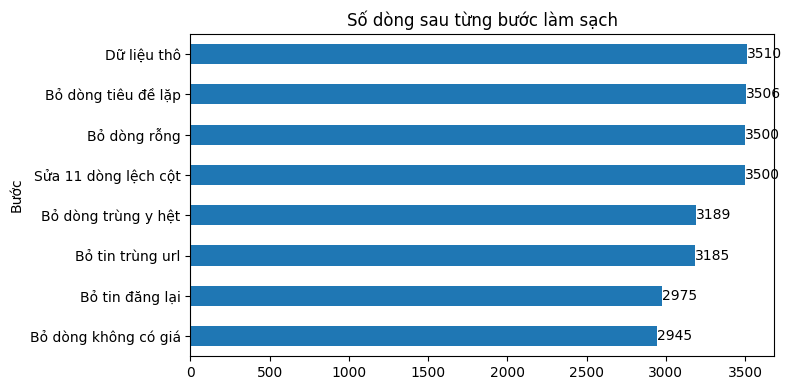

In [33]:
ax = steps.plot.barh(x="Bước", y="Số dòng", legend=False, figsize=(8, 4))
ax.invert_yaxis()
ax.bar_label(ax.containers[0])
ax.set_title("Số dòng sau từng bước làm sạch")
plt.tight_layout()

In [34]:
# So sánh cùng các căn trước và sau
o = clean["order"].astype(str).head(8).tolist()
show = ["order", "city", "district", "house_type", "area_m2", "floors", "bedrooms", "has_parking", "price_billion_vnd"]
print("TRƯỚC (dữ liệu thô)")
display(raw[raw["order"].isin(o)].drop_duplicates("order")[show])
print("SAU (dữ liệu sạch)")
clean[clean["order"].astype(str).isin(o)][show]

TRƯỚC (dữ liệu thô)


,order,city,district,house_type,area_m2,floors,bedrooms,has_parking,price_billion_vnd
0,1,Hà Nội,Quận Cầu Giấy,Nhà trong hẻm,0108,5.0,5.0,True,69.4 triệu/m²
1,2,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,1100.0,1.0,3.0.0,False,27000
2,3,Hà Nội,Bắc Từ Liêm,Hẻm,25.0,4.0,3.0,False,
3,4,Hồ Chí Minh,Gò Vấp.,Nhà trong hẻm,24.0,2.0,2.0,0,"2,9 tỷ VNĐ"
4,5,Hà Nội,Quận Long Biên,Nhà mặt tiền,70.0,4.0,6.0,True,7.0
5,6,Hà Nội,HÀ ĐÔNG,Nhà trong hẻm,55.0,5.0,4.0,False,"11,000,000,000 đ"
6,7,Hà Nội,hoàng mai,Nhà trong hẻm,65.0,4.0,4+,False,6.18
7,8,Hồ Chí Minh,10,nhà ngõ,5.9x20.0,0.0,4.0,False,16.7


SAU (dữ liệu sạch)


,order,city,district,house_type,area_m2,floors,bedrooms,has_parking,price_billion_vnd
0,1,Hà Nội,Cầu Giấy,Nhà trong hẻm,108.0,5,5,True,7.495
1,2,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,NaN,1,3,False,27.000
2,3,Hà Nội,Bắc Từ Liêm,Nhà trong hẻm,25.0,4,3,False,1.650
3,4,Hồ Chí Minh,Gò Vấp,Nhà trong hẻm,24.0,2,2,False,2.900
4,5,Hà Nội,Long Biên,Nhà mặt tiền,70.0,4,6,True,7.000
5,6,Hà Nội,Hà Đông,Nhà trong hẻm,55.0,5,4,False,11.000
6,7,Hà Nội,Hoàng Mai,Nhà trong hẻm,65.0,4,4,False,6.180
7,8,Hồ Chí Minh,Quận 10,Nhà trong hẻm,118.0,<NA>,4,False,16.700


In [35]:
# Số ô còn thiếu (sẽ điền ở bước mô hình hóa, sau khi chia train/test)
clean.isna().sum()[lambda s: s > 0].to_frame("Số ô thiếu")

,Số ô thiếu
title,8
posted_date,228
area_m2,6
width_m,846
length_m,1680
road_width_m,161
floors,226
bedrooms,188
has_dining_room,25
has_kitchen,41


# 4. Lưu kết quả
Ghi đè `data/processed/clean.csv` và `reports/cleaning_log.csv`. Dữ liệu gốc không bị sửa.

In [36]:
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
steps.rename(columns={"Bước": "buoc", "Số dòng": "so_dong"}).to_csv(LOG_PATH, index=False, encoding="utf-8")
print("Đã lưu", len(clean), "dòng vào", CLEAN_PATH.relative_to(ROOT))

Đã lưu 2945 dòng vào data/processed/clean.csv
